In [1]:
import sys
print(sys.executable)

C:\Users\HP\miniconda3\python.exe


In [3]:
import sys
print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
Python executable: C:\Users\HP\miniconda3\python.exe


In [4]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelBinarizer
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, skew
import seaborn as sns

%matplotlib inline

In [5]:
df=pd.read_csv('./Mall_Customers.csv')

In [6]:
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [8]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [9]:
df.drop('CustomerID',inplace=True,axis=1)

In [10]:
df.columns=['Gender','Age','Annual_Income','Spending_Score(1-100)']

In [11]:
df.describe()

,Age,Annual_Income,Spending_Score(1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


In [13]:
corr = df.corr(numeric_only=True)

print(corr)

                            Age  Annual_Income  Spending_Score(1-100)
Age                    1.000000      -0.012398              -0.327227
Annual_Income         -0.012398       1.000000               0.009903
Spending_Score(1-100) -0.327227       0.009903               1.000000


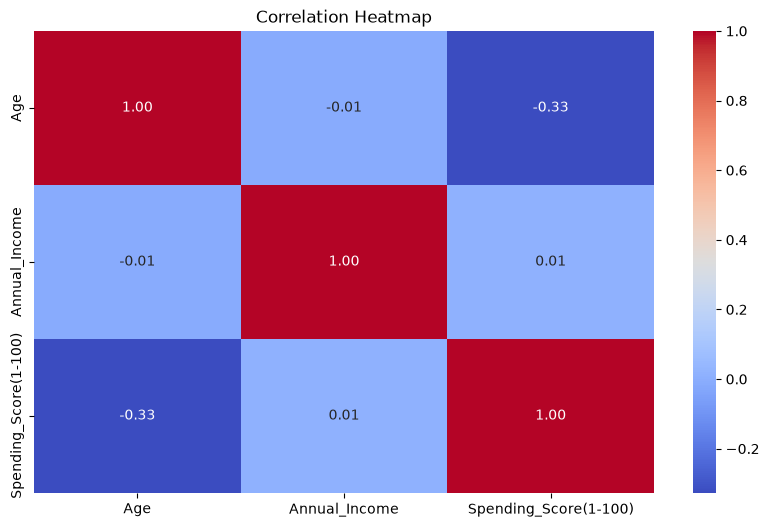

In [14]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

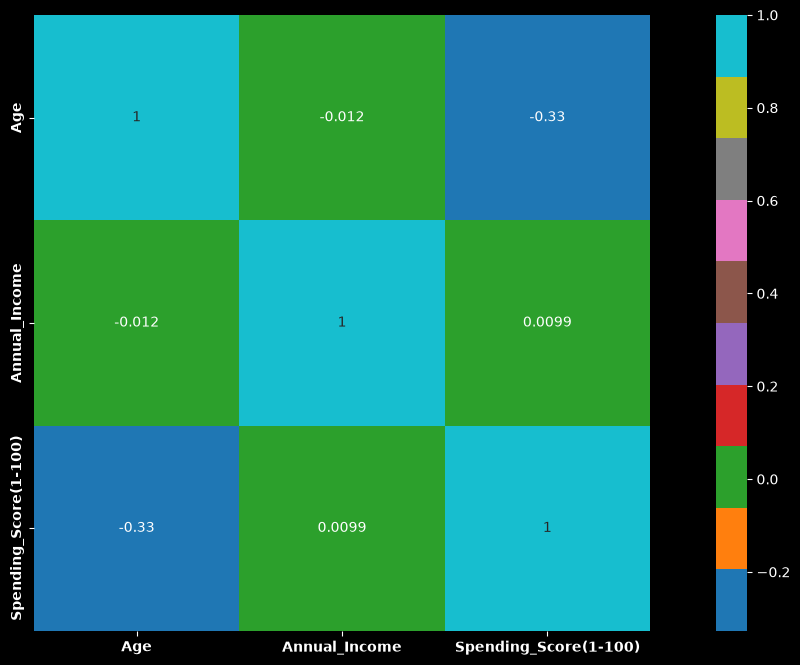

In [16]:
plt.style.use('dark_background')

plt.figure(figsize=(17, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    square=True,
    cmap='tab10'
)

plt.xticks(fontsize=10, fontweight='bold')
plt.yticks(fontsize=10, fontweight='bold')

plt.show()

<Figure size 1500x1000 with 0 Axes>

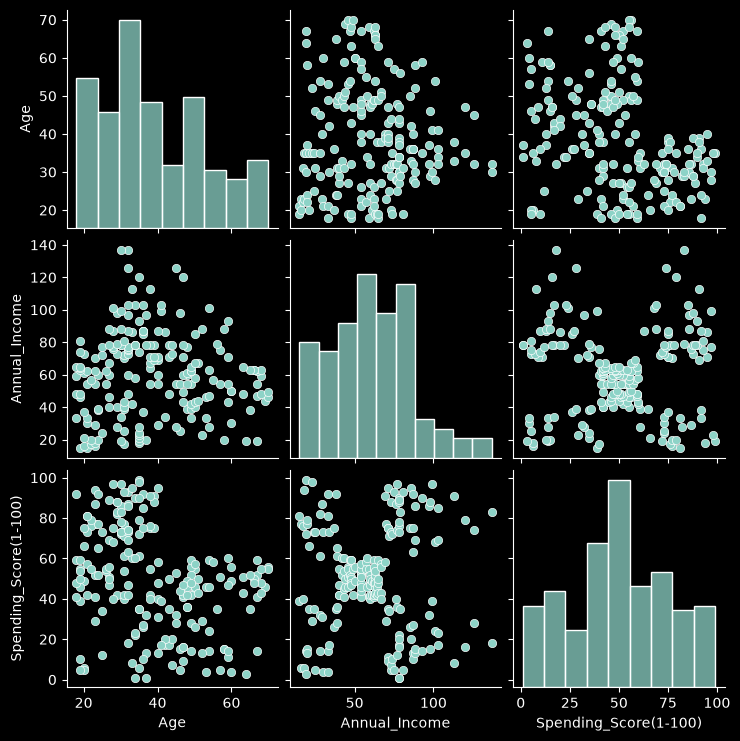

In [19]:
plt.style.use('dark_background')
plt.figure(figsize=(15,10))
sns.pairplot(df)

<Axes: >

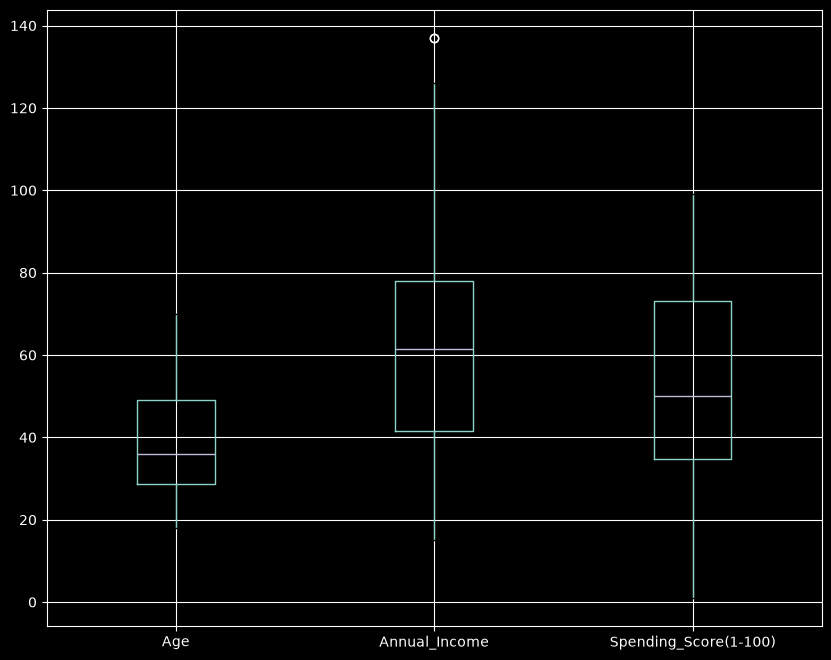

In [20]:
plt.figure(figsize=(10,8))
df.boxplot()

<Axes: ylabel='Density'>

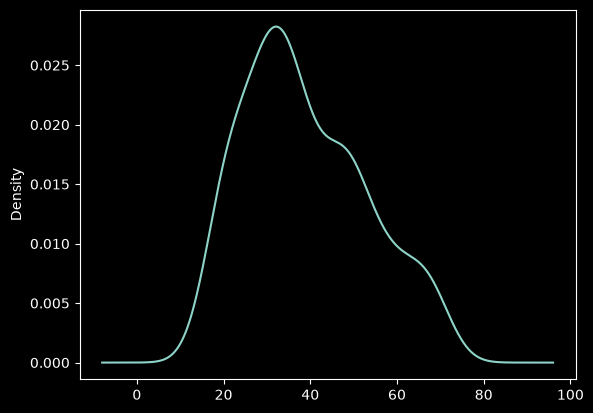

In [21]:
df['Age'].plot.kde()

<Axes: ylabel='Density'>

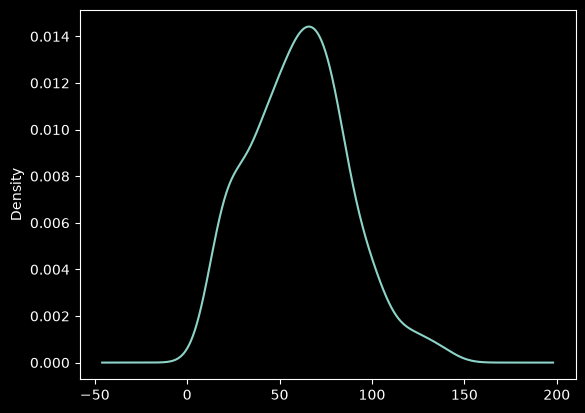

In [22]:
df['Annual_Income'].plot.kde()

<Axes: ylabel='Density'>

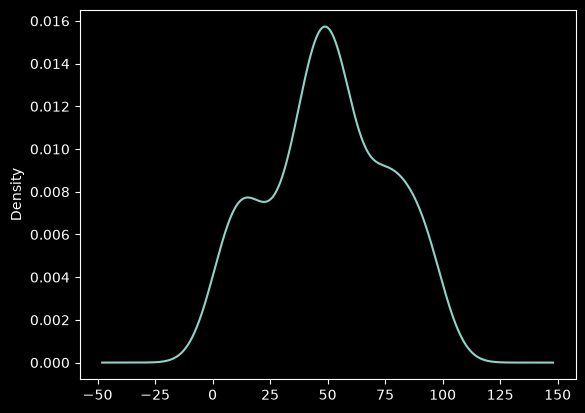

In [23]:
df['Spending_Score(1-100)'].plot.kde()

<Axes: xlabel='Gender', ylabel='Annual_Income'>

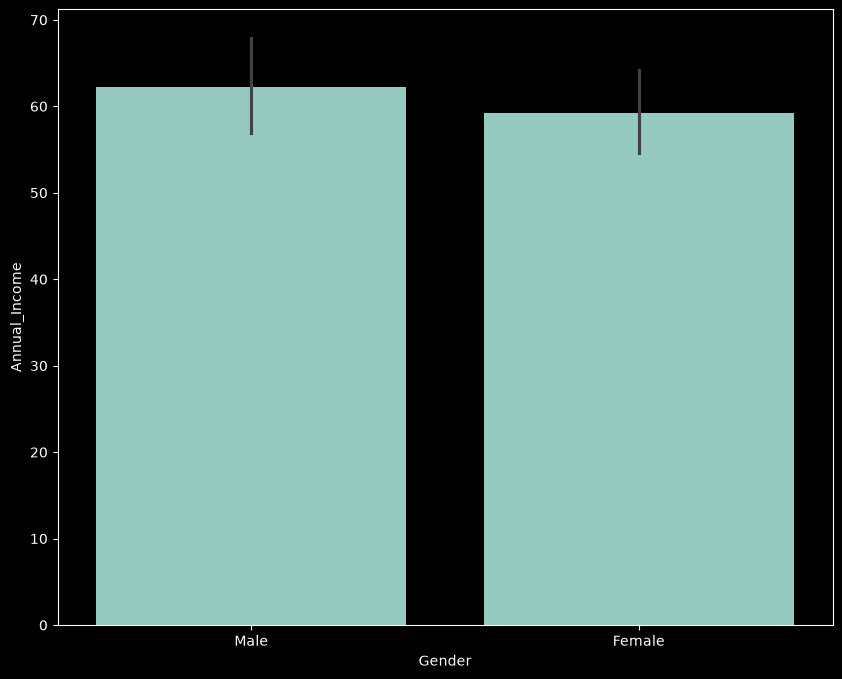

In [24]:
plt.figure(figsize=(10,8))
sns.barplot(x='Gender',y='Annual_Income',data=df)

<Axes: xlabel='Age', ylabel='Annual_Income'>

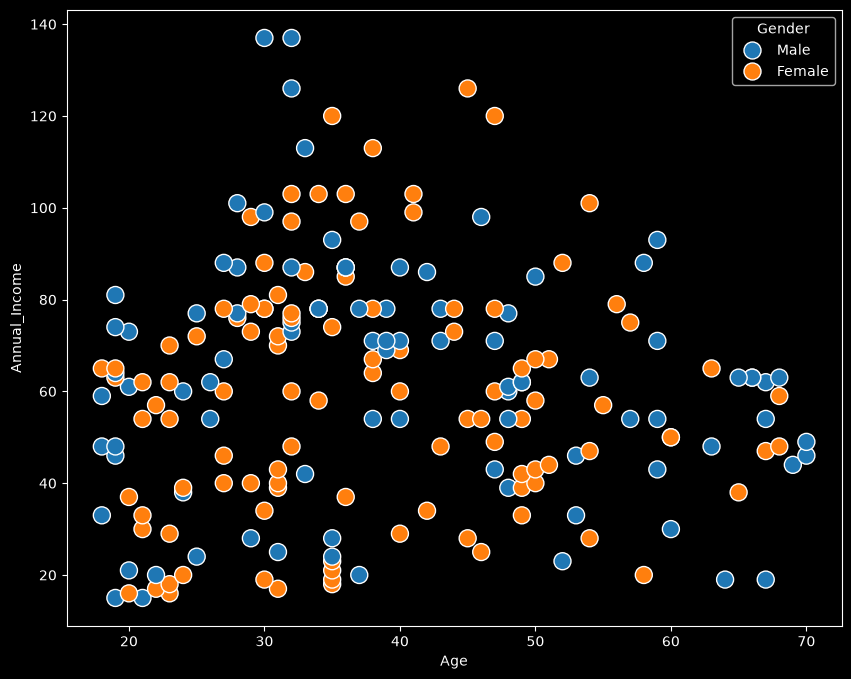

In [25]:
plt.figure(figsize=(10,8))
sns.scatterplot(x='Age',y='Annual_Income',hue='Gender',data=df,s=150,palette='tab10')

<Axes: xlabel='Spending_Score(1-100)', ylabel='Annual_Income'>

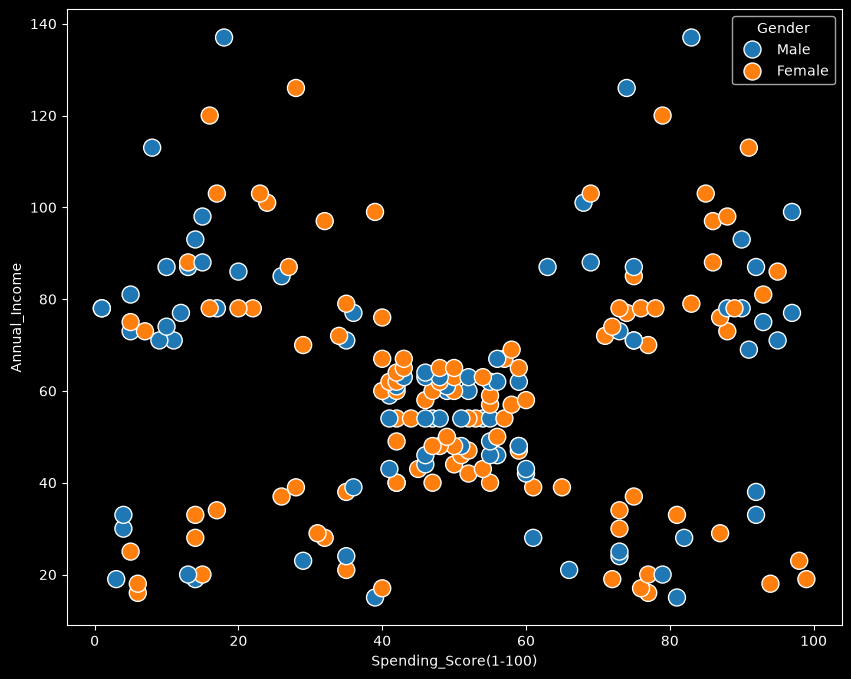

In [26]:
plt.figure(figsize=(10,8))
sns.scatterplot(x='Spending_Score(1-100)',y='Annual_Income',hue='Gender',data=df,s=150,palette='tab10')

In [33]:
encoder=LabelBinarizer()
df['Gender']=encoder.fit_transform(df['Gender'])

In [34]:
skew(df)

array([ 0.24174689,  0.48191947,  0.31942368, -0.04686531])

In [35]:
kurtosis(df)

array([-1.94155844, -0.68475139, -0.12589283, -0.83595827])

In [36]:
cluster_no=[i for i in range(1,12)]
WCSS=[]
for i in cluster_no:
    cluster=KMeans(init='k-means++',n_clusters=i,random_state=42)
    cluster.fit(df)
    WCSS.append(cluster.inertia_)

C:\Users\HP\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with M